# 02 — Safe YOLO + ByteTrack tracking pilot

This notebook tests tracking in a **separate Python worker process**. A worker crash or timeout should leave the Jupyter kernel available. The workload is deliberately small: one video, a maximum of 80 decoded frames, CPU inference, image size 320.

No OpenCV/PyTorch packages are installed, removed, upgraded, or modified. No `KMP_DUPLICATE_LIB_OK` workaround is used. The worker merely prioritizes PyTorch's bundled DLL directory within its own process and limits numerical-library thread counts.

In [1]:
from pathlib import Path
import json, os, sys, subprocess, time
import pandas as pd

PROJECT_DIR=Path(r"C:\Users\admin\ViTPose_Action_Recognition")
NOTEBOOK2_DIR=PROJECT_DIR/"Notebook_2_Improved_v2"
MANIFEST_PATH=PROJECT_DIR/"data"/"processed"/"manifest.csv"
YOLO_CANDIDATES=[PROJECT_DIR/"notebooks"/"yolo11n.pt",PROJECT_DIR/"yolo11n.pt"]
YOLO_WEIGHTS=next((p for p in YOLO_CANDIDATES if p.is_file()),None)
OUT_DIR=NOTEBOOK2_DIR/"data"/"tracking_pilot_v2"
LOG_DIR=NOTEBOOK2_DIR/"logs"/"tracking_pilot_v2"
SRC_DIR=NOTEBOOK2_DIR/"src"
for p in [OUT_DIR,LOG_DIR,SRC_DIR]: p.mkdir(parents=True,exist_ok=True)
assert MANIFEST_PATH.is_file(),f"Manifest missing: {MANIFEST_PATH}"
assert YOLO_WEIGHTS is not None,"yolo11n.pt was not found in the expected Notebook 1 locations."

PILOT_CLASS="Typing"
MAX_DECODED_FRAMES=80
FRAME_STRIDE=2
IMGSZ=320
CONF=0.20
MAX_DET=5
MAX_PREVIEWS=6

manifest=pd.read_csv(MANIFEST_PATH)
required={"video_path","label"}
missing=required-set(manifest.columns)
assert not missing,f"Manifest missing columns: {sorted(missing)}"
rows=manifest[manifest.label.astype(str).str.strip().str.casefold().eq(PILOT_CLASS.casefold())].sort_values("video_path")
assert not rows.empty,f"Class {PILOT_CLASS} not found in manifest"
video_path=Path(str(rows.iloc[0].video_path))
assert video_path.is_file(),f"Video not found: {video_path}"

CONFIG=OUT_DIR/"worker_config.json"
RESULT=OUT_DIR/"worker_result.json"
DETECTIONS=OUT_DIR/"detections.csv"
PREVIEW_DIR=OUT_DIR/"previews"
PREVIEW_DIR.mkdir(parents=True,exist_ok=True)
WORKER=SRC_DIR/"tracking_worker_v2.py"
WORKER.write_text('\nimport os, sys\nfrom pathlib import Path\n# Prefer PyTorch\'s bundled OpenMP DLL in the child process without modifying\n# the parent Jupyter environment or deleting any DLL/package.\ntorch_lib = Path(sys.prefix) / "Lib" / "site-packages" / "torch" / "lib"\nimport ctypes\n_openmp_handle = None\nif os.name == "nt":\n    _torch_iomp = torch_lib / "libiomp5md.dll"\n    if _torch_iomp.is_file():\n        try:\n            _openmp_handle = ctypes.WinDLL(str(_torch_iomp))\n            print("OPENMP_PRELOADED_FROM", _torch_iomp, flush=True)\n        except OSError as _dll_error:\n            print("OPENMP_PRELOAD_WARNING", repr(_dll_error), flush=True)\n_dll_handles = []\nif torch_lib.is_dir():\n    os.environ["PATH"] = str(torch_lib) + os.pathsep + os.environ.get("PATH", "")\n    if hasattr(os, "add_dll_directory"):\n        try:\n            _dll_handles.append(os.add_dll_directory(str(torch_lib)))\n        except OSError:\n            pass\nfor _name in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "NUMEXPR_NUM_THREADS"]:\n    os.environ[_name] = "1"\nos.environ["PYTHONUNBUFFERED"] = "1"\n\nimport json, time, gc, traceback\nfrom pathlib import Path\n\ncfg = json.loads(Path(sys.argv[1]).read_text(encoding="utf-8"))\ncap = None\ntry:\n    import torch\n    torch.set_num_threads(1)\n    import cv2\n    cv2.setNumThreads(1)\n    import numpy as np\n    import pandas as pd\n    from ultralytics import YOLO\n    print("WORKER_START",flush=True)\n    print("python",sys.executable,flush=True)\n    print("torch",torch.__version__,"cv2",cv2.__version__,flush=True)\n    print("weights",cfg["weights"],flush=True)\n    model=YOLO(cfg["weights"])\n    print("YOLO_LOADED",flush=True)\n    cap=cv2.VideoCapture(cfg["video_path"])\n    if not cap.isOpened(): raise RuntimeError("OpenCV could not open source video")\n    decoded=processed=det_frames=preview_count=0\n    track_counts={}; rows=[]; start=time.time()\n    outdir=Path(cfg["preview_dir"]); outdir.mkdir(parents=True,exist_ok=True)\n    while decoded < int(cfg["max_decoded_frames"]):\n        ok,frame=cap.read()\n        if not ok: break\n        frame_idx=decoded; decoded+=1\n        if frame_idx % int(cfg["frame_stride"]) != 0: continue\n        processed+=1\n        result=model.track(frame,persist=True,tracker="bytetrack.yaml",classes=[0],conf=float(cfg["conf"]),\n                           imgsz=int(cfg["imgsz"]),device="cpu",max_det=int(cfg["max_det"]),verbose=False)[0]\n        if result.boxes is not None and len(result.boxes):\n            boxes=result.boxes.xyxy.cpu().numpy(); confs=result.boxes.conf.cpu().numpy()\n            ids=result.boxes.id.cpu().numpy().astype(int) if result.boxes.id is not None else np.full(len(boxes),-1,dtype=int)\n            det_frames+=1\n            for box,score,tid in zip(boxes,confs,ids):\n                x1,y1,x2,y2=map(float,box); area=max(0.0,x2-x1)*max(0.0,y2-y1)\n                rows.append({"frame_index":int(frame_idx),"track_id":int(tid),"confidence":float(score),\n                             "x1":x1,"y1":y1,"x2":x2,"y2":y2,"area":area})\n                if tid>=0: track_counts[int(tid)]=track_counts.get(int(tid),0)+1\n            if preview_count<int(cfg["max_previews"]):\n                canvas=frame.copy()\n                for box,score,tid in zip(boxes,confs,ids):\n                    x1,y1,x2,y2=map(int,box); cv2.rectangle(canvas,(x1,y1),(x2,y2),(0,255,0),2)\n                    cv2.putText(canvas,f"ID {tid} {score:.2f}",(x1,max(18,y1-5)),cv2.FONT_HERSHEY_SIMPLEX,0.5,(0,255,0),2)\n                cv2.imwrite(str(outdir/f"frame_{frame_idx:06d}.jpg"),canvas); preview_count+=1\n        del result\n        if processed%5==0: print(f"PROGRESS decoded={decoded} processed={processed} detections={det_frames} tracks={len(track_counts)}",flush=True)\n        if processed%10==0: gc.collect()\n    cap.release(); cap=None\n    detpath=Path(cfg["detections_path"]); pd.DataFrame(rows).to_csv(detpath,index=False)\n    longest=max(track_counts,key=track_counts.get) if track_counts else -1\n    obj={"status":"success","video_path":cfg["video_path"],"label":cfg["label"],"decoded_frames":decoded,\n         "processed_frames":processed,"detection_frames":det_frames,"detection_frame_rate":det_frames/max(processed,1),\n         "tracked_ids":len(track_counts),"longest_track_id":int(longest),\n         "longest_track_observations":int(track_counts.get(longest,0)),"preview_frames":preview_count,\n         "detection_rows":len(rows),"seconds":round(time.time()-start,2)}\n    Path(cfg["result_path"]).write_text(json.dumps(obj,indent=2),encoding="utf-8")\n    print("WORKER_SUCCESS",json.dumps(obj),flush=True)\nexcept BaseException as exc:\n    print("WORKER_EXCEPTION",repr(exc),flush=True); traceback.print_exc(); sys.exit(2)\nfinally:\n    if cap is not None: cap.release()\n    gc.collect()\n',encoding="utf-8")
cfg={"video_path":str(video_path),"label":PILOT_CLASS,"weights":str(YOLO_WEIGHTS),
     "max_decoded_frames":MAX_DECODED_FRAMES,"frame_stride":FRAME_STRIDE,"imgsz":IMGSZ,
     "conf":CONF,"max_det":MAX_DET,"max_previews":MAX_PREVIEWS,
     "preview_dir":str(PREVIEW_DIR),"detections_path":str(DETECTIONS),"result_path":str(RESULT)}
CONFIG.write_text(json.dumps(cfg,indent=2),encoding="utf-8")
RESULT.unlink(missing_ok=True); DETECTIONS.unlink(missing_ok=True)
print("Selected video:",video_path)
print("YOLO weights:",YOLO_WEIGHTS)
print("Python worker:",sys.executable)
print("Pilot cap:",MAX_DECODED_FRAMES,"frames; every",FRAME_STRIDE,"frames; CPU; imgsz",IMGSZ)

Selected video: C:\Users\admin\ViTPose_Action_Recognition\data\raw\ucf_sports\Typing\v_Typing_g01_c01.avi
YOLO weights: C:\Users\admin\ViTPose_Action_Recognition\notebooks\yolo11n.pt
Python worker: C:\Users\admin\anaconda3\python.exe
Pilot cap: 80 frames; every 2 frames; CPU; imgsz 320


In [2]:
# Launch the worker. If a native library fails, only this child process should terminate.
stdout_path=LOG_DIR/"worker_stdout.log"
stderr_path=LOG_DIR/"worker_stderr.log"
env=os.environ.copy()
# These limits apply only to the child process; they do not alter Anaconda or Jupyter settings.
for key in ["OMP_NUM_THREADS","MKL_NUM_THREADS","OPENBLAS_NUM_THREADS","NUMEXPR_NUM_THREADS"]:
    env[key]="1"
torch_lib=Path(sys.prefix)/"Lib"/"site-packages"/"torch"/"lib"
if torch_lib.is_dir():
    env["PATH"]=str(torch_lib)+os.pathsep+env.get("PATH","")
print("Starting single-video worker...")
try:
    proc=subprocess.run([sys.executable,str(WORKER),str(CONFIG)],cwd=str(PROJECT_DIR),env=env,
                        capture_output=True,text=True,errors="replace",timeout=900)
    stdout=proc.stdout or ""; stderr=proc.stderr or ""; return_code=proc.returncode
except subprocess.TimeoutExpired as exc:
    stdout=(exc.stdout or ""); stderr=(exc.stderr or "")+"\nWORKER_TIMEOUT after 900 seconds"; return_code=124
stdout_path.write_text(stdout,encoding="utf-8",errors="replace")
stderr_path.write_text(stderr,encoding="utf-8",errors="replace")
print("Worker return code:",return_code)
print("--- STDOUT ---\n",stdout[-12000:])
print("--- STDERR ---\n",stderr[-12000:])
print("Logs:",stdout_path,stderr_path)
if return_code==0 and RESULT.is_file():
    print("TRACKING PILOT SUCCEEDED")
else:
    print("TRACKING WORKER FAILED OR TIMED OUT. Jupyter should remain available.")
    print("Do not increase the workload; inspect worker_stderr.log first.")

Starting single-video worker...
Worker return code: 3
--- STDOUT ---
 OPENMP_PRELOADED_FROM C:\Users\admin\anaconda3\Lib\site-packages\torch\lib\libiomp5md.dll
WORKER_START
python C:\Users\admin\anaconda3\python.exe
torch 2.7.1+cu118 cv2 4.13.0
weights C:\Users\admin\ViTPose_Action_Recognition\notebooks\yolo11n.pt
YOLO_LOADED

--- STDERR ---
 OMP: Error #15: Initializing libiomp5md.dll, but found libiomp5md.dll already initialized.
OMP: Hint This means that multiple copies of the OpenMP runtime have been linked into the program. That is dangerous, since it can degrade performance or cause incorrect results. The best thing to do is to ensure that only a single OpenMP runtime is linked into the process, e.g. by avoiding static linking of the OpenMP runtime in any library. As an unsafe, unsupported, undocumented workaround you can set the environment variable KMP_DUPLICATE_LIB_OK=TRUE to allow the program to continue to execute, but that may cause crashes or silently produce incorrect res

No successful worker result JSON exists.
Preview images: 1


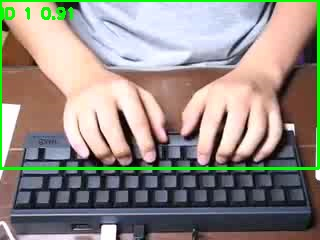

Diagnostic output folder: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\data\tracking_pilot_v2


In [3]:
from IPython.display import display, Image as IPyImage
if RESULT.is_file():
    result=json.loads(RESULT.read_text(encoding="utf-8"))
    display(pd.DataFrame([result]))
else:
    print("No successful worker result JSON exists.")
preview_files=sorted(PREVIEW_DIR.glob("*.jpg"))
print("Preview images:",len(preview_files))
for p in preview_files[:6]:
    display(IPyImage(filename=str(p)))
print("Diagnostic output folder:",OUT_DIR)

## Decision

Proceed to Notebook 03 only if the worker returns code 0 and the previews show credible person boxes and reasonably stable IDs. If it fails, share both worker logs; do not run the multi-video or full-dataset extraction. A subprocess reduces Jupyter-kernel risk but cannot guarantee that a native worker will never fail.